# MLT Assignment #1: Trees and Forests

## 1. Train 4 different classifiers:
- small decision tree;
- deep decision tree;
- random forest on small trees;
- random forest on deep trees;

Dataset: bioresponse.csv

In [35]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, log_loss

In [36]:
df = pd.read_csv('bioresponse.csv')

print(df.head())

X = df.drop(columns=['Activity'])
y = df['Activity']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

bioresponce_target = df.Activity.values
print('\nbioresponse = 1: {:.2f}\nbioresponse = 0: {:.2f}'.format(sum(bioresponce_target)/float(len(bioresponce_target)),
                1.0 - sum(bioresponce_target)/float(len(bioresponce_target))))

   Activity        D1        D2    D3   D4        D5        D6        D7  \
0         1  0.000000  0.497009  0.10  0.0  0.132956  0.678031  0.273166   
1         1  0.366667  0.606291  0.05  0.0  0.111209  0.803455  0.106105   
2         1  0.033300  0.480124  0.00  0.0  0.209791  0.610350  0.356453   
3         1  0.000000  0.538825  0.00  0.5  0.196344  0.724230  0.235606   
4         0  0.100000  0.517794  0.00  0.0  0.494734  0.781422  0.154361   

         D8        D9  ...  D1767  D1768  D1769  D1770  D1771  D1772  D1773  \
0  0.585445  0.743663  ...      0      0      0      0      0      0      0   
1  0.411754  0.836582  ...      1      1      1      1      0      1      0   
2  0.517720  0.679051  ...      0      0      0      0      0      0      0   
3  0.288764  0.805110  ...      0      0      0      0      0      0      0   
4  0.303809  0.812646  ...      0      0      0      0      0      0      0   

   D1774  D1775  D1776  
0      0      0      0  
1      0      1   

### Shallow decision tree

In [37]:
small_tree = DecisionTreeClassifier(max_depth=2, random_state=42)
small_tree.fit(X_train, y_train)

y_pred = small_tree.predict(X_test)
y_pred_proba = small_tree.predict_proba(X_test)[:, 1]

print("--- Shallow decision tree ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred):.4f}")
print(f"Log-loss:  {log_loss(y_test, y_pred_proba):.4f}")

--- Shallow decision tree ---
Accuracy:  0.7335
Precision: 0.7199
Recall:    0.8330
F1-score:  0.7723
Log-loss:  0.5767


### Deep decision tree

In [38]:
deep_tree = DecisionTreeClassifier(max_depth=None, random_state=42)
deep_tree.fit(X_train, y_train)

y_pred_deep = deep_tree.predict(X_test)
y_proba_deep = deep_tree.predict_proba(X_test)[:, 1]

print("--- Deep tree ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_deep):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_deep):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_deep):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_deep):.4f}")
print(f"Log-loss:  {log_loss(y_test, y_proba_deep):.4f}")

--- Deep tree ---
Accuracy:  0.7090
Precision: 0.7169
Recall:    0.7662
F1-score:  0.7407
Log-loss:  10.4903


### Random forest on small trees

In [39]:
random_forest = RandomForestClassifier(n_estimators=50, max_depth=2, random_state=42)
random_forest.fit(X_train, y_train)
y_pred_random_forest = random_forest.predict(X_test)
y_pred_random_forest_proba = random_forest.predict_proba(X_test)[:, 1]

print("--- Random forest on small trees ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_random_forest):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_random_forest):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_random_forest):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_random_forest):.4f}")
print(f"Log-loss:  {log_loss(y_test, y_pred_random_forest_proba):.4f}")

--- Random forest on small trees ---
Accuracy:  0.6642
Precision: 0.6559
Recall:    0.8016
F1-score:  0.7215
Log-loss:  0.6314


### Random forest on deep trees

In [40]:
deep_random_forest = RandomForestClassifier(max_depth=None, random_state=42)
deep_random_forest.fit(X_train, y_train)
y_pred_deep_random_forest = deep_random_forest.predict(X_test)
y_pred_deep_random_forest_proba = deep_random_forest.predict_proba(X_test)[:, 1]

print("--- Random forest on deep trees ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_deep_random_forest):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_deep_random_forest):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_deep_random_forest):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_deep_random_forest):.4f}")
print(f"Log-loss:  {log_loss(y_test, y_pred_deep_random_forest_proba):.4f}")

--- Random forest on deep trees ---
Accuracy:  0.7740
Precision: 0.7797
Recall:    0.8134
F1-score:  0.7962
Log-loss:  0.4784


## 3. Plot precision-recall and ROC curves for models.

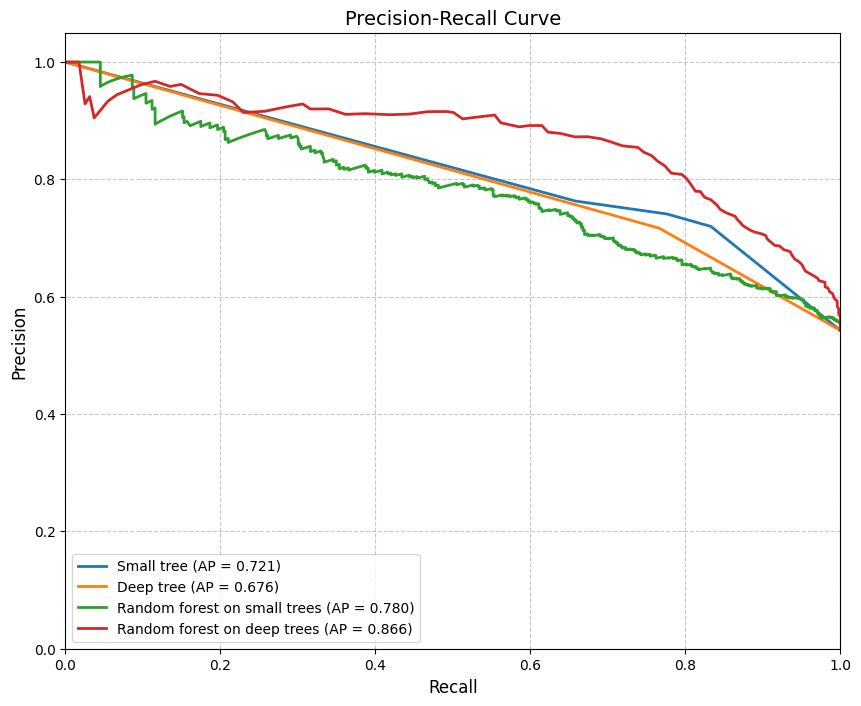

In [41]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(10, 8))

models = [
    ("Small tree", y_pred_proba),
    ("Deep tree", y_proba_deep),
    ("Random forest on small trees", y_pred_random_forest_proba),
    ("Random forest on deep trees", y_pred_deep_random_forest_proba)
]

for name, proba in models:
    precision, recall, _ = precision_recall_curve(y_test, proba)
    ap_score = average_precision_score(y_test, proba)
    plt.plot(recall, precision, label=f'{name} (AP = {ap_score:.3f})', lw=2)

plt.xlabel('Recall', fontsize=12)
plt.ylabel('Precision', fontsize=12)
plt.title('Precision-Recall Curve', fontsize=14)
plt.legend(loc='lower left', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.7)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])

plt.show()

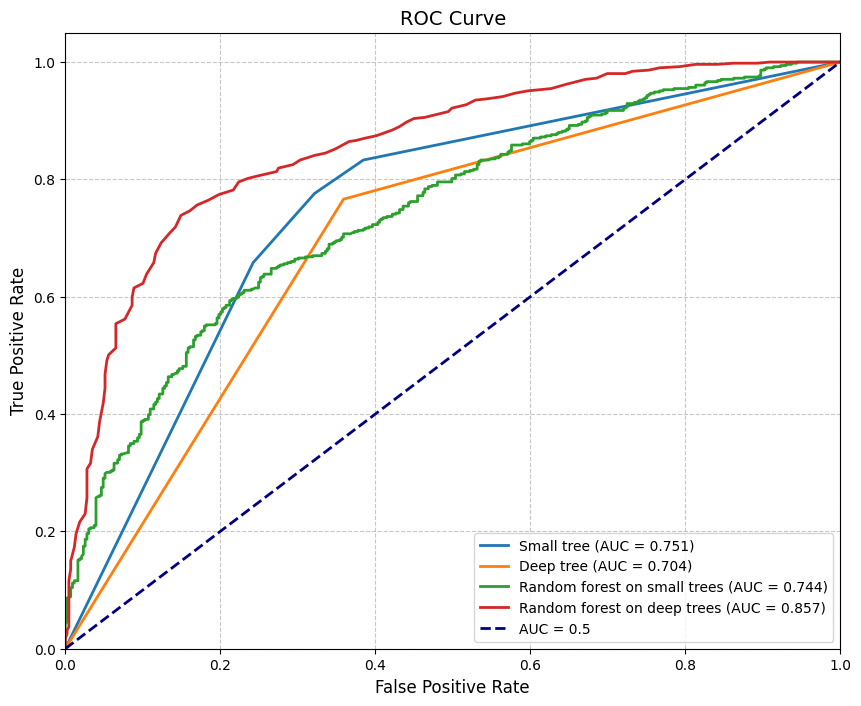

In [42]:
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(10, 8))

models = [
    ("Small tree", y_pred_proba),
    ("Deep tree", y_proba_deep),
    ("Random forest on small trees", y_pred_random_forest_proba),
    ("Random forest on deep trees", y_pred_deep_random_forest_proba)
]

for name, proba in models:
    fpr, tpr, _ = roc_curve(y_test, proba)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='AUC = 0.5')

plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curve', fontsize=14)
plt.legend(loc='lower right', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.7)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])

plt.show()

## 4. Train a classifier who avoids Type II (False Negative) errors and calculate metrics

In [43]:
deep_random_forest = RandomForestClassifier(max_depth=None, random_state=42)
deep_random_forest.fit(X_train, y_train)
y_pred_deep_random_forest = deep_random_forest.predict(X_test)
y_pred_deep_random_forest_proba = deep_random_forest.predict_proba(X_test)[:, 1]

custom_threshold = 0.2
y_pred_custom = (y_pred_deep_random_forest_proba >= custom_threshold).astype(int)

print("--- Forest on deep trees (enhanced) ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_custom):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_custom):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_custom):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_custom):.4f}")
print(f"Log-loss:  {log_loss(y_test, y_pred_deep_random_forest_proba):.4f}")

--- Forest on deep trees (enhanced) ---
Accuracy:  0.6482
Precision: 0.6085
Recall:    0.9862
F1-score:  0.7526
Log-loss:  0.4784
